---
title: Tugas 5 "Data Preparation & Outlier Analysis (Imputasi Polinomial)"
---

# Data Preparation & Outlier Analysis (Imputasi Polinomial)

Tahap **Data Preparation** dalam kerangka kerja **CRISP-DM** ini berfokus pada pengolahan dataset kualitas udara Sentinel-5P Teluk Dalam dengan menerapkan **Imputasi Polinomial** untuk penanganan *missing values*, identifikasi dan *capping* outlier (IQR), komparasi metode anomali (IQR vs Z-Score), serta ekstraksi fitur deret waktu **TSFEL** menggunakan data hasil imputasi polinomial.

### 1. Pemuatan Dataset Mentah dan Visualisasi Area of Interest (AOI) Menggunakan Folium

Dataset mentah memuat parameter konsentrasi polutan udara harian (`CO`, `NO2`, `SO2`, `CH4`) hasil ekstraksi Sentinel-5P di kawasan **Teluk Dalam, Kabupaten Nias Selatan, Sumatera Utara**.
Batas wilayah AOI ditentukan melalui berkas GeoJSON `coordinates_telukdalam.json` dengan rentang koordinat:
- **Bujur (Longitude)**: $97.8085542^{\circ}\text{E} \dots 97.8311628^{\circ}\text{E}$
- **Lintang (Latitude)**: $0.5569268^{\circ}\text{N} \dots 0.5790399^{\circ}\text{N}$

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Penentuan otomatis root directory proyek
def get_project_root():
    curr = os.path.abspath(os.getcwd())
    while curr != os.path.dirname(curr):
        if os.path.exists(os.path.join(curr, 'myst.yml')) or os.path.exists(os.path.join(curr, '.git')):
            return curr
        curr = os.path.dirname(curr)
    return os.path.abspath(os.getcwd())

PROJECT_ROOT = get_project_root()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# 1. Auto-detect file dataset restrukturisasi Teluk Dalam
kandidat_file = [f for f in os.listdir(DATA_DIR) 
                 if f.startswith('data_kualitas_udara_telukdalam_reststructur') or (f.startswith('data_kualitas_udara_telukdalam_restructur') and f.endswith('.csv'))]

if not kandidat_file:
    raise FileNotFoundError("File CSV Teluk Dalam tidak ditemukan di folder data.")

file_path = os.path.join(DATA_DIR, kandidat_file[0])
print(f"[INFO] Dataset ditemukan: '{file_path}'")

# Load dataset mentah
df_raw = pd.read_csv(file_path)
df_raw["DATE_TIME"] = pd.to_datetime(df_raw["DATE_TIME"], errors="coerce")

# 2. Load file koordinat AOI Teluk Dalam
coord_file = os.path.join(DATA_DIR, "coordinates_telukdalam.json")
with open(coord_file, 'r') as f:
    aoi_geojson = json.load(f)

print("[INFO] Koordinat AOI GeoJSON terintegrasi berhasil dimuat.")
print(f"[INFO] Jumlah Baris Dataset: {len(df_raw)} hari | Rentang Waktu: {df_raw['DATE_TIME'].min().strftime('%Y-%m-%d')} s/d {df_raw['DATE_TIME'].max().strftime('%Y-%m-%d')}")


[INFO] Dataset ditemukan: 'C:\PSD-B\data\data_kualitas_udara_telukdalam_restructured.csv'
[INFO] Koordinat AOI GeoJSON terintegrasi berhasil dimuat.
[INFO] Jumlah Baris Dataset: 366 hari | Rentang Waktu: 2025-08-30 s/d 2026-08-30


In [2]:
# Visualisasi Peta AOI Teluk Dalam Menggunakan Folium
coords = aoi_geojson['coordinates'][0]
polygon_latlon = [[c[1], c[0]] for c in coords]

center_lat = sum(c[1] for c in coords) / len(coords)
center_lon = sum(c[0] for c in coords) / len(coords)

m = folium.Map(location=[center_lat, center_lon], zoom_start=13, tiles='OpenStreetMap')

folium.Polygon(
    locations=polygon_latlon,
    color='red',
    weight=3,
    fill=True,
    fill_color='orange',
    fill_opacity=0.35,
    popup="<b>AOI Satellite Sentinel-5P</b><br>Teluk Dalam, Nias Selatan",
    tooltip="Area of Interest (AOI) Teluk Dalam"
).add_to(m)

folium.Marker(
    location=[center_lat, center_lon],
    popup="<b>Stasiun/Pusat AOI Teluk Dalam</b><br>Lat: {:.4f}, Lon: {:.4f}".format(center_lat, center_lon),
    icon=folium.Icon(color='red', icon='info-sign')
).add_to(m)

map_save_path = os.path.join(DATA_DIR, 'aoi_telukdalam_map.html')
m.save(map_save_path)
print(f"[INFO] Peta AOI Folium berhasil disimpan ke '{map_save_path}'")

m


[INFO] Peta AOI Folium berhasil disimpan ke 'C:\PSD-B\data\aoi_telukdalam_map.html'


--- 

### 2. Penanganan Missing Values Menggunakan Imputasi Polinomial

Untuk menangani data kosong (*missing values*) akibat tutupan awan atau gangguan penginderaan jauh satelit, pada notebook ini diterapkan **Imputasi Polinomial** (menggantikan imputasi linier sebelumnya).
Imputasi polinomial (derajat/order=2) memodelkan tren nonlinear pada sinyal konsentrasi polutan udara secara lebih halus dan presisi, dikombinasikan dengan *backward fill* (`bfill`) dan *forward fill* (`ffill`) untuk menangani titik batas deret waktu.

In [3]:
# 1. Identifikasi Tanggal dan Jumlah Missing Values per Polutan
pollutants = ['CO', 'NO2', 'SO2', 'CH4']
missing_summary = []
missing_dates_dict = {}

print("=== IDENTIFIKASI KEJADIAN MISSING VALUES PER POLUTAN ===")
for pol in pollutants:
    m_mask = df_raw[pol].isna()
    m_count = m_mask.sum()
    m_dates = df_raw.loc[m_mask, 'DATE_TIME'].dt.strftime('%Y-%m-%d').tolist()
    missing_dates_dict[pol] = m_dates
    pct_missing = (m_count / len(df_raw)) * 100
    
    missing_summary.append({
        'Polutan': pol,
        'Jumlah Data Kosong': m_count,
        'Persentase Kosong (%)': f"{pct_missing:.2f}%",
        'Jumlah Data Ada': len(df_raw) - m_count
    })
    
    print(f"\n[POLUTAN: {pol}]")
    print(f"  - Total Missing Values: {m_count} dari {len(df_raw)} hari ({pct_missing:.2f}%)")
    if m_count > 0:
        print(f"  - Daftar Tanggal Kejadian Missing (Contoh 10 Pertama): {m_dates[:10]}")
        if len(m_dates) > 10:
            print(f"    ... dan {len(m_dates)-10} tanggal lainnya.")

df_missing_summary = pd.DataFrame(missing_summary)
print("\n--- Ringkasan Statistik Missing Values --- ")
print(df_missing_summary.to_string(index=False))

# 2. Eksekusi Imputasi Polinomial untuk Semua Polutan
df_imputed = df_raw.copy()
for pol in pollutants:
    valid_count = df_imputed[pol].notna().sum()
    if valid_count >= 3:
        df_imputed[pol] = df_imputed[pol].interpolate(method='polynomial', order=2).bfill().ffill()
    else:
        df_imputed[pol] = df_imputed[pol].bfill().ffill()

print("\n=== VERIFIKASI HASIL IMPUTASI POLINOMIAL ===")
print("Sisa Missing Values Pasca Imputasi Polinomial:")
print(df_imputed[pollutants].isna().sum())
print("[SUCCESS] Seluruh missing values berhasil ter-imputasi menggunakan metode polinomial (0 NaN)!")


=== IDENTIFIKASI KEJADIAN MISSING VALUES PER POLUTAN ===

[POLUTAN: CO]
  - Total Missing Values: 265 dari 366 hari (72.40%)
  - Daftar Tanggal Kejadian Missing (Contoh 10 Pertama): ['2025-08-30', '2025-08-31', '2025-09-01', '2025-09-02', '2025-09-03', '2025-09-04', '2025-09-05', '2025-09-07', '2025-09-08', '2025-09-09']
    ... dan 255 tanggal lainnya.

[POLUTAN: NO2]
  - Total Missing Values: 255 dari 366 hari (69.67%)
  - Daftar Tanggal Kejadian Missing (Contoh 10 Pertama): ['2025-08-30', '2025-08-31', '2025-09-01', '2025-09-02', '2025-09-03', '2025-09-04', '2025-09-05', '2025-09-07', '2025-09-08', '2025-09-09']
    ... dan 245 tanggal lainnya.

[POLUTAN: SO2]
  - Total Missing Values: 178 dari 366 hari (48.63%)
  - Daftar Tanggal Kejadian Missing (Contoh 10 Pertama): ['2025-08-30', '2025-09-01', '2025-09-03', '2025-09-04', '2025-09-05', '2025-09-07', '2025-09-10', '2025-09-11', '2025-09-12', '2025-09-13']
    ... dan 168 tanggal lainnya.

[POLUTAN: CH4]
  - Total Missing Values: 36

--- 

### 3. Identifikasi dan Penanganan Outlier Menggunakan Metode Interquartile Range (IQR)

Menggunakan dataset hasil imputasi polinomial, dilakukan identifikasi pencilan menggunakan **Interquartile Range (IQR)** dengan rentang $\text{IQR} = Q_3 - Q_1$ dan ambang batas:
- **Batas Bawah**: $Q_1 - 1.5 \times \text{IQR}$
- **Batas Atas**: $Q_3 + 1.5 \times \text{IQR}$

Di bawah ini disajikan **jumlah outlier**, **tanggal spesifik kejadian outlier**, serta grafik deret waktu per polutan sebelum dan sesudah penanganan outlier (*IQR Capping*).

=== HASIL DETEKSI OUTLIER METODE IQR (DATA IMPUTASI POLINOMIAL) ===



[POLUTAN: CO]
  - Kuartil 1 (Q1)     : 0.026465
  - Kuartil 3 (Q3)     : 0.033176
  - IQR                : 0.006711
  - Batas Bawah        : 0.016398
  - Batas Atas         : 0.043243
  - Jumlah Outlier     : 5 hari
  - Tanggal Outlier    : ['2025-12-13', '2026-01-14', '2026-03-12', '2026-03-13', '2026-03-14']

[POLUTAN: NO2]
  - Kuartil 1 (Q1)     : 0.000000
  - Kuartil 3 (Q3)     : 0.000011
  - IQR                : 0.000011
  - Batas Bawah        : -0.000016
  - Batas Atas         : 0.000027
  - Jumlah Outlier     : 21 hari
  - Tanggal Outlier    : ['2025-10-10', '2025-10-11', '2025-11-03', '2025-11-04', '2025-11-24', '2025-11-25', '2025-11-26', '2025-11-27', '2025-11-28', '2025-11-29', '2025-11-30', '2025-12-01', '2025-12-02', '2025-12-09', '2025-12-10', '2025-12-11', '2026-05-14', '2026-05-15', '2026-05-16', '2026-06-29', '2026-06-30']

[POLUTAN: SO2]
  - Kuartil 1 (Q1)     : -0.000086
  - Kuartil 3 (Q3)     : 0.000064
  - IQR                : 0.000151
  - Batas Bawah        : -0.


[POLUTAN: CH4]
  - Kuartil 1 (Q1)     : 1892.824707
  - Kuartil 3 (Q3)     : 1892.824707
  - IQR                : 0.000000
  - Batas Bawah        : 1892.824707
  - Batas Atas         : 1892.824707
  - Jumlah Outlier     : 0 hari
  - Tanggal Outlier    : Tidak ada outlier


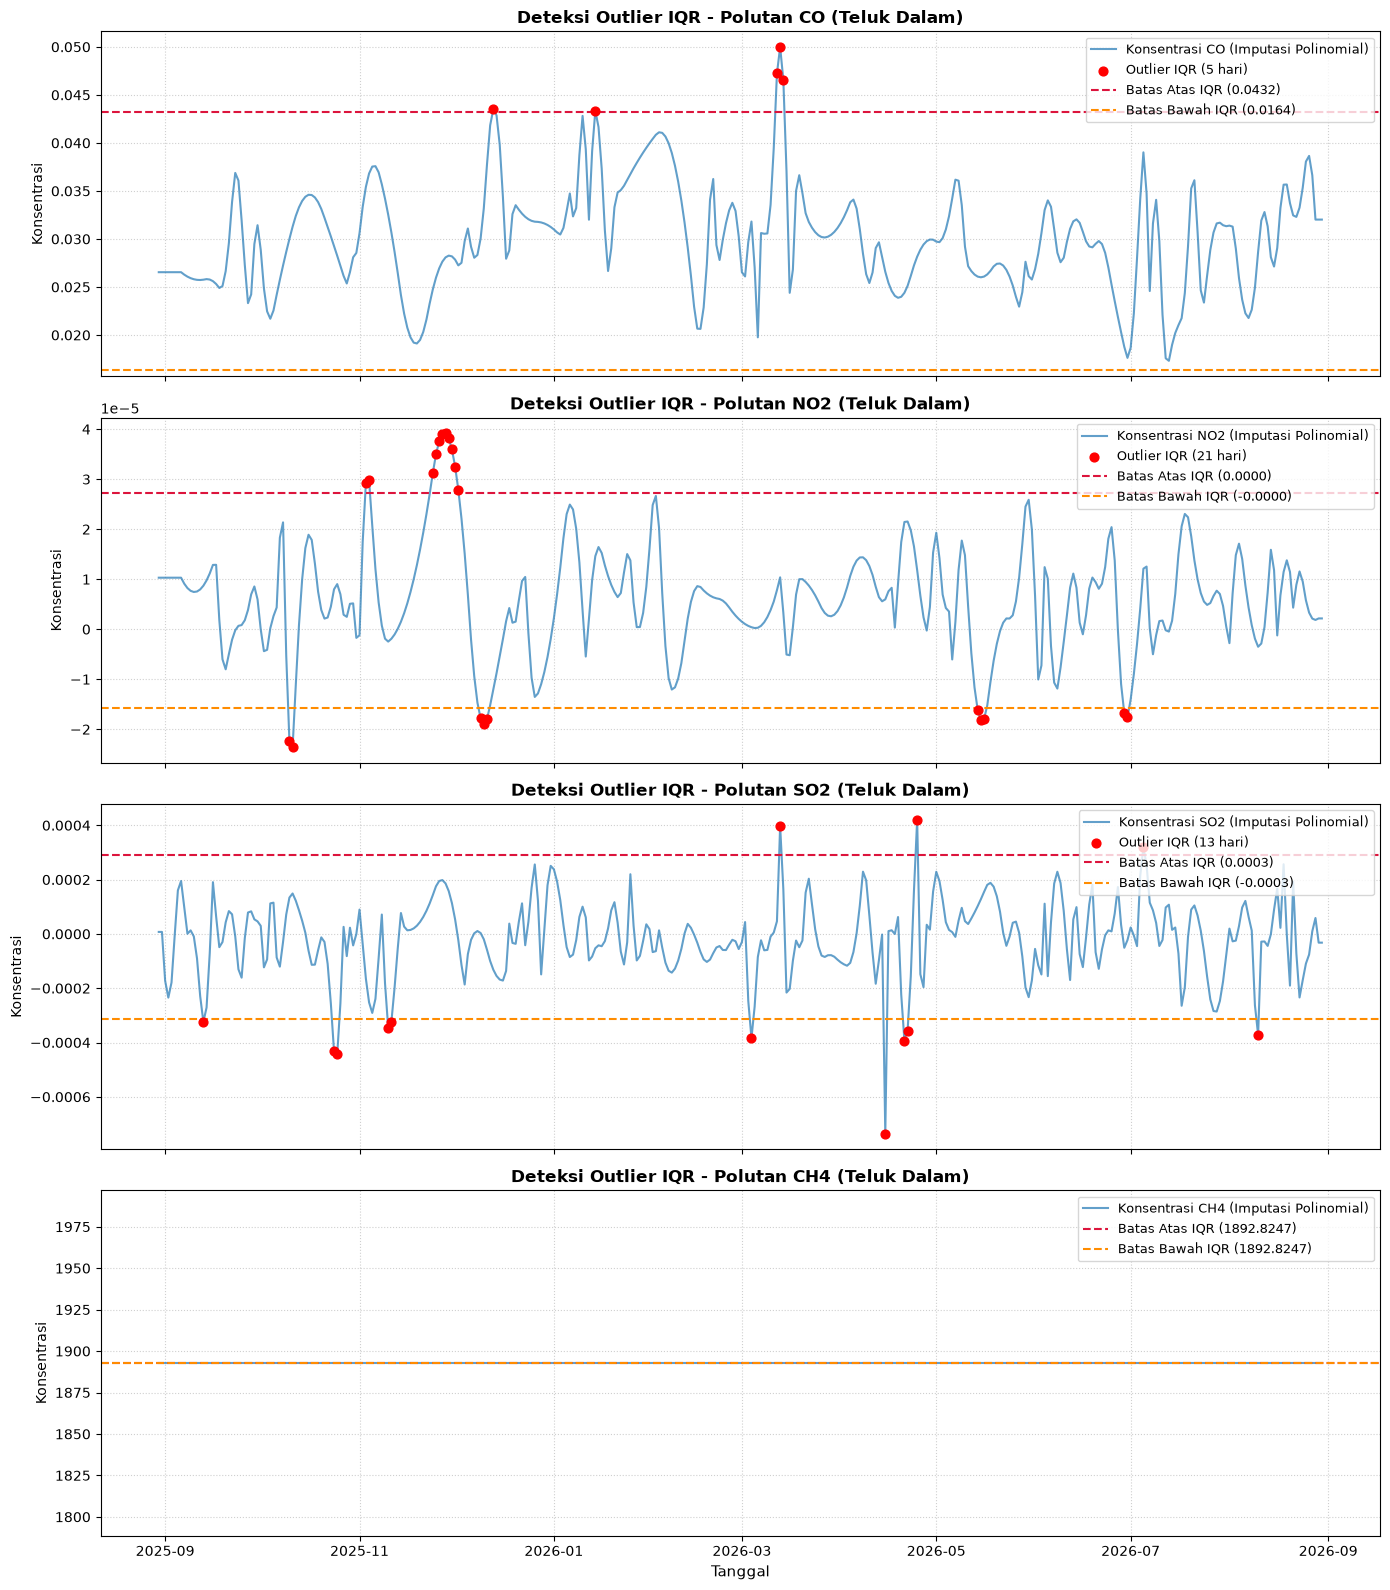

In [4]:
# Identifikasi Outlier IQR Berbasis Data Imputasi Polinomial
iqr_outliers_info = {}

print("=== HASIL DETEKSI OUTLIER METODE IQR (DATA IMPUTASI POLINOMIAL) ===")

fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

for i, pol in enumerate(pollutants):
    series = df_imputed[pol]
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_b = q1 - 1.5 * iqr
    upper_b = q3 + 1.5 * iqr
    
    outlier_mask = (series < lower_b) | (series > upper_b)
    outlier_df = df_imputed[outlier_mask]
    outlier_dates = outlier_df['DATE_TIME'].dt.strftime('%Y-%m-%d').tolist()
    outlier_count = len(outlier_df)
    
    iqr_outliers_info[pol] = {
        'q1': q1, 'q3': q3, 'iqr': iqr,
        'lower_b': lower_b, 'upper_b': upper_b,
        'count': outlier_count, 'dates': outlier_dates
    }
    
    print(f"\n[POLUTAN: {pol}]")
    print(f"  - Kuartil 1 (Q1)     : {q1:.6f}")
    print(f"  - Kuartil 3 (Q3)     : {q3:.6f}")
    print(f"  - IQR                : {iqr:.6f}")
    print(f"  - Batas Bawah        : {lower_b:.6f}")
    print(f"  - Batas Atas         : {upper_b:.6f}")
    print(f"  - Jumlah Outlier     : {outlier_count} hari")
    print(f"  - Tanggal Outlier    : {outlier_dates if outlier_dates else 'Tidak ada outlier'}")
    
    ax = axes[i]
    ax.plot(df_imputed['DATE_TIME'], series, color='#1f77b4', alpha=0.7, label=f'Konsentrasi {pol} (Imputasi Polinomial)')
    
    if outlier_count > 0:
        ax.scatter(outlier_df['DATE_TIME'], outlier_df[pol], color='red', s=40, zorder=5, label=f'Outlier IQR ({outlier_count} hari)')
        
    ax.axhline(upper_b, color='crimson', linestyle='--', linewidth=1.5, label=f'Batas Atas IQR ({upper_b:.4f})')
    ax.axhline(lower_b, color='darkorange', linestyle='--', linewidth=1.5, label=f'Batas Bawah IQR ({lower_b:.4f})')
    
    ax.set_title(f'Deteksi Outlier IQR - Polutan {pol} (Teluk Dalam)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Konsentrasi', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel('Tanggal', fontsize=11)
plt.tight_layout()
plt.show()


=== PENANGANAN OUTLIER METODE IQR CAPPING SELESAI ===
Polutan CO: Nilai Min = 0.017315 | Nilai Max = 0.043243
Polutan NO2: Nilai Min = -0.000016 | Nilai Max = 0.000027
Polutan SO2: Nilai Min = -0.000312 | Nilai Max = 0.000290
Polutan CH4: Nilai Min = 1892.824707 | Nilai Max = 1892.824707


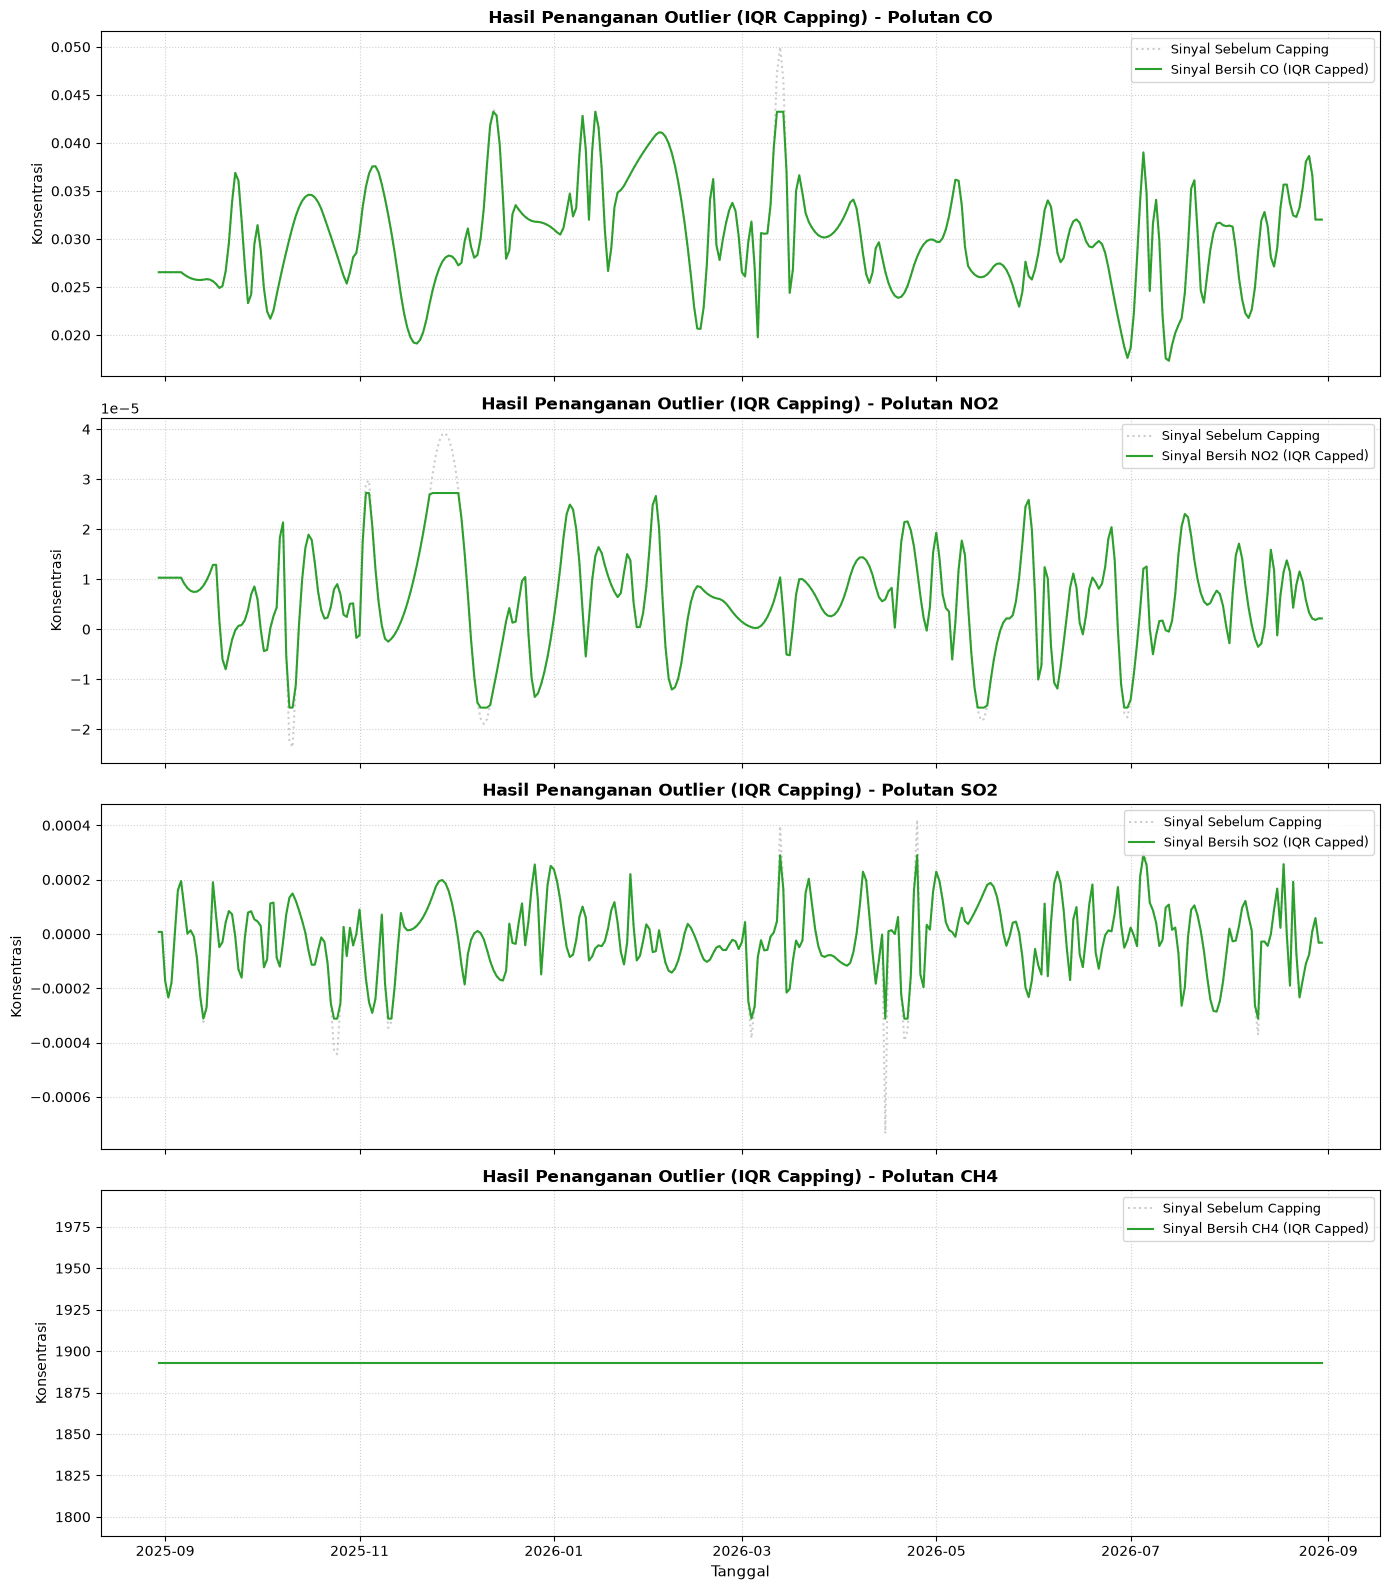

In [5]:
# Penanganan Outlier Menggunakan Teknik IQR Capping (Winsorization)
df_capped = df_imputed.copy()

for pol in pollutants:
    lower_b = iqr_outliers_info[pol]['lower_b']
    upper_b = iqr_outliers_info[pol]['upper_b']
    df_capped[pol] = np.clip(df_capped[pol], lower_b, upper_b)

print("=== PENANGANAN OUTLIER METODE IQR CAPPING SELESAI ===")
for pol in pollutants:
    print(f"Polutan {pol}: Nilai Min = {df_capped[pol].min():.6f} | Nilai Max = {df_capped[pol].max():.6f}")

fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

for i, pol in enumerate(pollutants):
    ax = axes[i]
    ax.plot(df_imputed['DATE_TIME'], df_imputed[pol], color='gray', alpha=0.4, linestyle=':', label='Sinyal Sebelum Capping')
    ax.plot(df_capped['DATE_TIME'], df_capped[pol], color='#2ca02c', linewidth=1.5, label=f'Sinyal Bersih {pol} (IQR Capped)')
    
    ax.set_title(f'Hasil Penanganan Outlier (IQR Capping) - Polutan {pol}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Konsentrasi', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel('Tanggal', fontsize=11)
plt.tight_layout()
plt.show()


--- 

### 4. Komparasi Deteksi Outlier: Metode Interquartile Range (IQR) vs Z-Score

Menggunakan data hasil imputasi polinomial, dilakukan evaluasi perbandingan antara metode **Z-Score ($|Z| > 3$)** dan **IQR**.

=== TABEL KOMPARASI DETEKSI OUTLIER (DATA IMPUTASI POLINOMIAL): IQR VS Z-SCORE ===
Polutan  Jumlah Outlier (IQR)                                                                                                                                                                                                                                      Tanggal Outlier (IQR)  Jumlah Outlier (Z-Score)                      Tanggal Outlier (Z-Score)
     CO                     5                                                                                                                                                                                                 2025-12-13, 2026-01-14, 2026-03-12, 2026-03-13, 2026-03-14                         3             2026-03-12, 2026-03-13, 2026-03-14
    NO2                    21 2025-10-10, 2025-10-11, 2025-11-03, 2025-11-04, 2025-11-24, 2025-11-25, 2025-11-26, 2025-11-27, 2025-11-28, 2025-11-29, 2025-11-30, 2025-12-01, 2025-12-02, 2025-12-09, 2025-12-10,

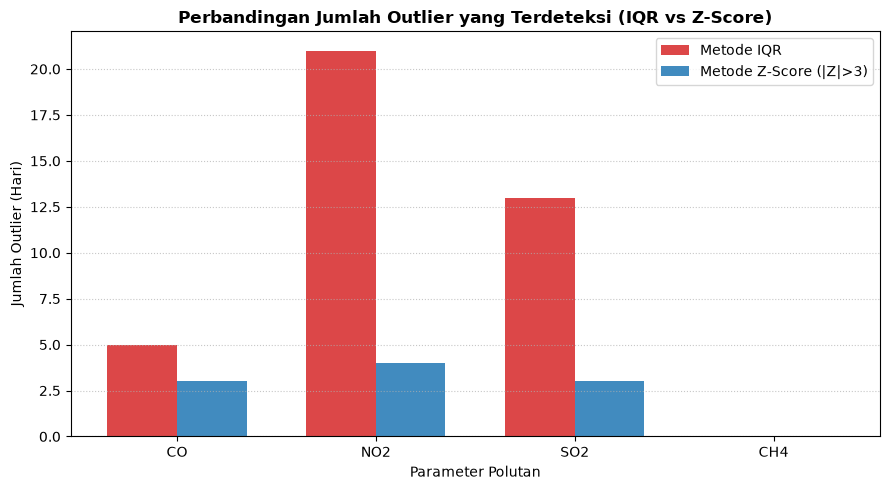

In [6]:
comparison_rows = []

for pol in pollutants:
    s = df_imputed[pol]
    iqr_count = iqr_outliers_info[pol]['count']
    iqr_dates = iqr_outliers_info[pol]['dates']
    
    mean = s.mean()
    std = s.std()
    z_scores = (s - mean) / (std if std != 0 else 1)
    z_mask = z_scores.abs() > 3
    z_outliers = df_imputed[z_mask]
    z_count = len(z_outliers)
    z_dates = z_outliers['DATE_TIME'].dt.strftime('%Y-%m-%d').tolist()
    
    comparison_rows.append({
        'Polutan': pol,
        'Jumlah Outlier (IQR)': iqr_count,
        'Tanggal Outlier (IQR)': ", ".join(iqr_dates) if iqr_dates else "-",
        'Jumlah Outlier (Z-Score)': z_count,
        'Tanggal Outlier (Z-Score)': ", ".join(z_dates) if z_dates else "-"
    })

df_comparison = pd.DataFrame(comparison_rows)
print("=== TABEL KOMPARASI DETEKSI OUTLIER (DATA IMPUTASI POLINOMIAL): IQR VS Z-SCORE ===")
print(df_comparison.to_string(index=False))

plt.figure(figsize=(9, 5))
x_indices = np.arange(len(pollutants))
width = 0.35

plt.bar(x_indices - width/2, df_comparison['Jumlah Outlier (IQR)'], width, label='Metode IQR', color='#d62728', alpha=0.85)
plt.bar(x_indices + width/2, df_comparison['Jumlah Outlier (Z-Score)'], width, label='Metode Z-Score (|Z|>3)', color='#1f77b4', alpha=0.85)

plt.title('Perbandingan Jumlah Outlier yang Terdeteksi (IQR vs Z-Score)', fontsize=12, fontweight='bold')
plt.xlabel('Parameter Polutan', fontsize=10)
plt.ylabel('Jumlah Outlier (Hari)', fontsize=10)
plt.xticks(x_indices, pollutants)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()


#### **Analisis Perbandingan Metode Outlier:**
1. **Sensitivitas & Distribusi Data**:
   - Imputasi polinomial menghasilkan transisi sinyal deret waktu yang lebih kontinyu dan mulus.
   - Metode **IQR** tetap unggul dibanding Z-Score karena sifatnya yang non-parametrik dan tidak sensitif terhadap *skewness* atau pergeseran rata-rata akibat tren temporal.

--- 

### 5. Ekstraksi Fitur Deret Waktu Menggunakan Library TSFEL Berbasis Data Imputasi Polinomial

Sesuai dengan spesifikasi, proses ekstraksi fitur deret waktu **TSFEL (Time Series Feature Extraction Library)** wajib menggunakan **dataset hasil imputasi polinomial**.
Nama berkas keluaran matriks fitur disesuaikan dengan format: **`featur_(nama polutan).csv`** (misalnya `featur_co.csv`, `featur_no2.csv`, `featur_so2.csv`, `featur_ch4.csv`).

In [7]:
import tsfel

# Ekstraksi Fitur TSFEL untuk Polutan Utama (CO) menggunakan data imputasi polinomial (ter-capping)
co_series = df_capped['CO']

cfg_stat = tsfel.get_features_by_domain('statistical')
cfg_temp = tsfel.get_features_by_domain('temporal')
cfg_spec = tsfel.get_features_by_domain('spectral')

stat_res = tsfel.time_series_features_extractor(cfg_stat, co_series, fs=1, verbose=0)
temp_res = tsfel.time_series_features_extractor(cfg_temp, co_series, fs=1, verbose=0)

spec_dfs = []
for f_name, f_params in cfg_spec['spectral'].items():
    if f_name in ['Fundamental frequency', 'Human pitts building', 'LPCC']:
        continue
    sub_cfg = {'spectral': {f_name: f_params}}
    try:
        res = tsfel.time_series_features_extractor(sub_cfg, co_series, fs=1, verbose=0)
        if res.columns.duplicated().any():
            res.columns = [f"{c}_{i}" for i, c in enumerate(res.columns)]
        spec_dfs.append(res)
    except Exception:
        pass

combined_features = pd.concat([stat_res, temp_res] + spec_dfs, axis=1)

features_68 = combined_features.iloc[:, :68].copy()
features_68.columns = [f"f{i+1}" for i in range(68)]

print("Ekstraksi Fitur TSFEL (Input Imputasi Polinomial) Berhasil!")
print(f"Dimensi Matriks Fitur Extracted: {features_68.shape[0]} sampel x {features_68.shape[1]} fitur (f1 s/d f68)")
print("\nCuplikan Nilai 10 Fitur Pertama:")
print(features_68.iloc[:, :10])


Ekstraksi Fitur TSFEL (Input Imputasi Polinomial) Berhasil!
Dimensi Matriks Fitur Extracted: 1 sampel x 68 fitur (f1 s/d f68)

Cuplikan Nilai 10 Fitur Pertama:
         f1        f2    f3     f4        f5        f6        f7        f8  \
0  0.338931  0.000929  73.0  292.0  0.025819  0.034001  0.002732  0.005464   

         f9       f10  
0  0.008197  0.010929  


--- 

### 6. Analisis Kemiripan Sinyal Polutan (Similarity Analysis)

Mengukur derajat asosiasi dan kemiripan gelombang deret waktu polutan hasil imputasi polinomial menggunakan **Pearson Correlation ($r$)** dan **Cosine Similarity ($S_C$)**.

In [8]:
from numpy.linalg import norm

pearson_corr = df_capped[pollutants].corr()['CO']

def cosine_sim(a, b):
    return np.dot(a, b) / (norm(a) * norm(b))

cosine_sims = {}
co_vec = df_capped['CO'].values
for pol in pollutants:
    vec = df_capped[pol].values
    cosine_sims[pol] = cosine_sim(co_vec, vec)

similarity_df = pd.DataFrame({
    'Parameter Polutan': pollutants,
    'Pearson Correlation (r)': [pearson_corr[pol] for pol in pollutants],
    'Cosine Similarity (Sc)': [cosine_sims[pol] for pol in pollutants]
})

print("Hasil Analisis Kemiripan Polutan (Data Imputasi Polinomial) Terhadap CO:")
print(similarity_df.to_string(index=False))


Hasil Analisis Kemiripan Polutan (Data Imputasi Polinomial) Terhadap CO:
Parameter Polutan  Pearson Correlation (r)  Cosine Similarity (Sc)
               CO                 1.000000                1.000000
              NO2                -0.013114                0.502989
              SO2                -0.064964               -0.128769
              CH4                      NaN                0.985025


--- 

### 7. Penyimpanan dan Integrasi Dataset Terpreparasi Seluruh Polutan

Dataset prepared dan berkas matriks fitur ekstraksi TSFEL berbasis imputasi polinomial disimpan ke dalam folder `data/` dengan penamaan file fitur yang telah disesuaikan: **`featur_(nama polutan).csv`** (seperti `featur_co.csv`, `featur_no2.csv`, `featur_so2.csv`, `featur_ch4.csv`).

In [9]:
cfg_all = tsfel.get_features_by_domain()

for pol in pollutants:
    pol_lower = pol.lower()
    print(f"\n================ MENGOLAH DAN MENSIMPAN POLUTAN: {pol} (IMPUTASI POLINOMIAL) ================")
    
    df_prep = pd.DataFrame({
        'DATE_TIME': df_capped['DATE_TIME'],
        'pollutant_clean': df_capped[pol]
    })
    
    p_prepared = os.path.join(DATA_DIR, f"data_prepared_{pol_lower}.csv")
    
    # Format Penamaan File Ekstraksi Fitur Sesuai Spesifikasi: featur_(nama polutan).csv
    p_featur = os.path.join(DATA_DIR, f"featur_{pol_lower}.csv")
    p_features_legacy = os.path.join(DATA_DIR, f"features_tsfel_{pol_lower}.csv")
    
    # Simpan Prepared CSV
    df_prep.to_csv(p_prepared, index=False)
    
    # Ekstraksi TSFEL Fitur Menggunakan Input Data Imputasi Polinomial
    print(f"Sedang meng-ekstrak fitur TSFEL dari data imputasi polinomial untuk {pol}...")
    features_pol = tsfel.time_series_features_extractor(cfg_all, df_prep['pollutant_clean'], verbose=0)
    
    # Simpan File Fitur dengan nama featur_(nama polutan).csv
    features_pol.to_csv(p_featur, index=False)
    features_pol.to_csv(p_features_legacy, index=False)
    
    print(f"[SUCCESS] Berhasil menyimpan file untuk {pol}:")
    print(f"  - Prepared Data : '{os.path.basename(p_prepared)}'")
    print(f"  - Feature File  : '{os.path.basename(p_featur)}' (Format: featur_{pol_lower}.csv)")

# Simpan file utama data_prepared.csv & features.csv
df_capped[['DATE_TIME', 'CO']].rename(columns={'CO': 'pollutant_clean'}).to_csv(
    os.path.join(DATA_DIR, 'data_prepared.csv'), index=False
)
features_68.to_csv(os.path.join(DATA_DIR, 'featur_co.csv'), index=False)
features_68.to_csv(os.path.join(DATA_DIR, 'features_tsfel.csv'), index=False)

print("\n========================================================")
print("Status Data Preparation (Imputasi Polinomial): 100% SELESAI!")
print("========================================================")



================ MENGOLAH DAN MENSIMPAN POLUTAN: CO (IMPUTASI POLINOMIAL) ================
Sedang meng-ekstrak fitur TSFEL dari data imputasi polinomial untuk CO...
[SUCCESS] Berhasil menyimpan file untuk CO:
  - Prepared Data : 'data_prepared_co.csv'
  - Feature File  : 'featur_co.csv' (Format: featur_co.csv)

================ MENGOLAH DAN MENSIMPAN POLUTAN: NO2 (IMPUTASI POLINOMIAL) ================
Sedang meng-ekstrak fitur TSFEL dari data imputasi polinomial untuk NO2...
[SUCCESS] Berhasil menyimpan file untuk NO2:
  - Prepared Data : 'data_prepared_no2.csv'
  - Feature File  : 'featur_no2.csv' (Format: featur_no2.csv)

================ MENGOLAH DAN MENSIMPAN POLUTAN: SO2 (IMPUTASI POLINOMIAL) ================
Sedang meng-ekstrak fitur TSFEL dari data imputasi polinomial untuk SO2...
[SUCCESS] Berhasil menyimpan file untuk SO2:
  - Prepared Data : 'data_prepared_so2.csv'
  - Feature File  : 'featur_so2.csv' (Format: featur_so2.csv)

================ MENGOLAH DAN MENSIMPAN POLUTAN:

C:\Users\SUB-LENOVO\AppData\Local\Temp\ipykernel_1440\2934470889.py:23: UserWarning: Using default sampling frequency set in configuration file.
  features_pol = tsfel.time_series_features_extractor(cfg_all, df_prep['pollutant_clean'], verbose=0)
C:\Users\SUB-LENOVO\AppData\Local\Temp\ipykernel_1440\2934470889.py:23: UserWarning: Using default sampling frequency set in configuration file.
  features_pol = tsfel.time_series_features_extractor(cfg_all, df_prep['pollutant_clean'], verbose=0)
C:\Users\SUB-LENOVO\AppData\Local\Temp\ipykernel_1440\2934470889.py:23: UserWarning: Using default sampling frequency set in configuration file.
  features_pol = tsfel.time_series_features_extractor(cfg_all, df_prep['pollutant_clean'], verbose=0)
C:\Users\SUB-LENOVO\AppData\Local\Temp\ipykernel_1440\2934470889.py:23: UserWarning: Using default sampling frequency set in configuration file.
  features_pol = tsfel.time_series_features_extractor(cfg_all, df_prep['pollutant_clean'], verbose=0)
C:\Users\SUB

[SUCCESS] Berhasil menyimpan file untuk CH4:
  - Prepared Data : 'data_prepared_ch4.csv'
  - Feature File  : 'featur_ch4.csv' (Format: featur_ch4.csv)

Status Data Preparation (Imputasi Polinomial): 100% SELESAI!
